# Early ICU Treatment Effects and Patient Transitions
### SDS 4215 Final Project
### Ethan Engelman
**Objective:** Given a patient's current state and treatment, what happens in the next 4-hour window?

**Focus:** IV fluids, severity progression, short-term outcomes, and heterogeneity across patient groups.

# Roadmap

1. Define the research question and data structure  
2. Preprocess high-dimensional ICU data  
3. Explore outcomes, treatments, and severity  
4. Model hospital survival as a baseline task  
5. Cluster early treatment patterns  
6. Build dynamic transition models  
7. Estimate fluid-treatment associations and heterogeneity  
8. Evaluate reliability and limitations

# Specific Questions Addressed

**Main question:** How are early treatments associated with patient outcomes?

**Transition questions:**

- Given current state and treatment, what is the patient's **next SOFA score**?
- Will the patient **remain**, be **discharged**, or **die** in the next 4-hour window?
- Does the relationship between fluid treatment and outcomes vary by **age** or **baseline severity**?

**Interest:**
  - Focusing on the first 24 hours is important because it captures the critical early phase of ICU care, when patients are most unstable and key treatment decisions (like fluids, vasopressors, and ventilation) are made

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, mean_squared_error, r2_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Data Structure

The dataset contains one row per ICU stay for static files and one row per **4-hour window** for dynamic files.

| File | Grain | Role |
|---|---:|---|
| `cohort.csv` | ICU stay | Mortality labels |
| `context.csv` | ICU stay | Age, gender, weight, comorbidity |
| `state_4h.csv` | 4-hour window | Vitals, labs, GCS, urine output |
| `action_continuous.csv` | 4-hour window | Vasopressors, IV fluids, ventilation |
| `sofa_4h.csv` | 4-hour window | SOFA and SIRS severity scores |
| `outcome_4h.csv` | 4-hour window | Terminal outcome labels |

# Modeling Design

The analysis has two layers:

### 1. Early ICU summary model
Compress first 24 hours into one row per ICU stay.

Goal: predict overall hospital survival and understand early treatment patterns.

### 2. Dynamic transition model
Keep the 4-hour window structure.

Goal: model `state_{t} + treatment_{t} → state/outcome_{t+1}`.

In [4]:
cohort = pd.read_csv("/Users/Ethan/Downloads/cohort.csv")
context = pd.read_csv("/Users/Ethan/Downloads/context.csv")
sofa = pd.read_csv("/Users/Ethan/Downloads/sofa_4h.csv")
state = pd.read_csv("/Users/Ethan/Downloads/state_4h.csv")
actions = pd.read_csv("/Users/Ethan/Downloads/action_continuous.csv")
actions_disc = pd.read_csv("/Users/Ethan/Downloads/action_discrete.csv")
outcome = pd.read_csv("/Users/Ethan/Downloads/outcome_4h.csv")

# Preprocessing Step 1: Time Alignment

Each file uses `days` and `hourrange`, so I created a continuous time variable:

```python
hour_from_admission = days * 24 + (hourrange - 1) * 4
```

**Why this matters:**

This puts SOFA, vitals, treatments, and outcomes on the same 4-hour timeline so they can be merged by `icustay_id` and time.

# Preprocessing Step 2: Early 24-Hour Summary

For the first analysis, I restricted to the first 24 hours after ICU admission.

I summarized:

- Severity: mean/max SOFA and SIRS
- Treatment: total/max fluids, total/max vasopressors, any ventilation
- Timing: first fluid hour and first vasopressor hour
- State: average vitals, labs, GCS, and urine output

**Why this helps:**

It creates a patient-level dataset for understanding early treatment intensity and overall hospital survival.

In [5]:
for data in [sofa, state, actions, actions_disc, outcome]:
    data["hour_from_admission"] = data["days"] * 24 + (data["hourrange"] - 1) * 4

sofa_early = sofa[sofa["hour_from_admission"] < 24]
state_early = state[state["hour_from_admission"] < 24]
actions_early = actions[actions["hour_from_admission"] < 24]
disc_early = actions_disc[actions_disc["hour_from_admission"] < 24]
outcome_early = outcome[outcome["hour_from_admission"] < 24]

In [6]:
severity = sofa_early.groupby("icustay_id").agg(
    sofa_mean=("sofa", "mean"),
    sofa_max=("sofa", "max"),
    sirs_mean=("sirs", "mean"),
    sirs_max=("sirs", "max")
).reset_index()
severity.head()

,icustay_id,sofa_mean,sofa_max,sirs_mean,sirs_max
0,200001,2.000000,3,2.500000,3
1,200003,4.000000,4,3.500000,4
2,200012,0.333333,1,2.333333,3
3,200014,5.000000,5,2.000000,2
4,200018,0.000000,0,2.000000,2


In [7]:
treatment = actions_early.groupby("icustay_id").agg(
    vaso_total=("vaso_ne_per_kg", "sum"),
    vaso_max=("vaso_ne_per_kg", "max"),
    fluid_total=("fluid_total_ml", "sum"),
    fluid_max=("fluid_total_ml", "max"),
    mechvent_any=("mechvent", "max")
).reset_index()
treatment.head()

,icustay_id,vaso_total,vaso_max,fluid_total,fluid_max,mechvent_any
0,200001,0.0,0.0,36.166668,36.166668,0
1,200003,0.0,0.0,4011.083333,4011.083333,0
2,200012,0.0,0.0,0.000000,0.000000,0
3,200014,0.0,0.0,580.000000,580.000000,1
4,200018,0.0,0.0,0.000000,0.000000,0


In [8]:
def first_treatment_hour(data, column):
    treated = data[data[column].fillna(0) > 0]
    return treated.groupby("icustay_id")["hour_from_admission"].min()

treatment["first_vaso_hour"] = treatment["icustay_id"].map(
    first_treatment_hour(actions_early, "vaso_ne_per_kg")
).fillna(24)

treatment["first_fluid_hour"] = treatment["icustay_id"].map(
    first_treatment_hour(actions_early, "fluid_total_ml")
).fillna(24)

treatment["early_vaso"] = (treatment["first_vaso_hour"] < 24).astype(int)
treatment["early_fluid"] = (treatment["first_fluid_hour"] < 24).astype(int)

treatment.head(10)

,icustay_id,vaso_total,vaso_max,fluid_total,fluid_max,mechvent_any,first_vaso_hour,first_fluid_hour,early_vaso,early_fluid
0,200001,0.000000,0.000000,36.166668,36.166668,0,24.0,20.0,0,1
1,200003,0.000000,0.000000,4011.083333,4011.083333,0,24.0,20.0,0,1
2,200012,0.000000,0.000000,0.000000,0.000000,0,24.0,24.0,0,0
3,200014,0.000000,0.000000,580.000000,580.000000,1,24.0,20.0,0,1
4,200018,0.000000,0.000000,0.000000,0.000000,0,24.0,24.0,0,0
5,200021,0.000000,0.000000,1374.616668,1374.616668,1,24.0,20.0,0,1
6,200024,0.055935,0.055935,2036.785401,2036.785401,1,16.0,16.0,1,1
7,200025,0.001128,0.000772,2830.018186,1372.105746,1,12.0,12.0,1,1
8,200028,0.072918,0.072918,1243.679079,1054.418354,1,16.0,16.0,1,1
9,200049,0.000000,0.000000,1077.999993,389.833334,0,24.0,8.0,0,1


# Missingness Strategy

The state data contains substantial missingness. In ICU data, missingness often means a measurement was not taken, which may itself reflect clinical severity.

My approach:

- Drop variables with more than 80% missingness
- Keep clinically meaningful variables with moderate missingness
- Use median imputation inside model pipelines

**Interpretation:** This avoids losing many patients while still limiting extremely sparse variables.

In [9]:
state_numeric = state_early.select_dtypes(include=["int64", "float64"])

state_numeric["icustay_id"] = state_early["icustay_id"]

state_features = state_numeric.groupby("icustay_id").mean().reset_index()

missing_rates = state_features.isna().mean()
keep_cols = missing_rates[missing_rates < 0.80].index

state_features = state_features[keep_cols]

state_features.head()

,icustay_id,days,hourrange,vital_hr,vital_sbp,vital_dbp,vital_mbp,vital_rr,vital_temp_c,vital_spo2,...,bg_pao2fio2,vital_fio2,uo_total_ml,gcs_total,gcs_motor,gcs_verbal,gcs_eyes,gcs_endotrachflag,mechvent,hour_from_admission
0,200001,0.0,5.5,111.375000,111.625000,65.250000,76.625000,22.750000,37.472222,95.875000,...,NaN,NaN,250.0,15.0,6.0,5.0,4.0,0.0,0.0,18.0
1,200003,0.0,5.5,124.150000,96.611111,60.833333,66.777778,28.450000,38.953703,96.150000,...,NaN,NaN,320.0,15.0,6.0,5.0,4.0,0.0,0.0,18.0
2,200012,0.0,3.0,96.138889,103.500000,73.333333,80.166667,21.027778,37.092593,97.138889,...,NaN,NaN,600.0,15.0,6.0,5.0,4.0,0.0,0.0,8.0
3,200014,0.0,6.0,73.666667,110.333333,59.000000,76.111135,10.666667,35.666667,99.500000,...,NaN,40.0,215.0,15.0,1.0,0.0,1.0,1.0,1.0,20.0
4,200018,0.0,4.0,150.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,12.0


In [10]:
outcome_features = outcome_early.groupby("icustay_id").agg(
    terminal_early=("is_terminal", "max")
).reset_index()

outcome_features.head()

,icustay_id,terminal_early
0,200001,0
1,200003,0
2,200012,1
3,200014,0
4,200018,1


In [11]:
df = treatment.merge(severity, on="icustay_id", how="left")
df = df.merge(state_features, on="icustay_id", how="left")
df = df.merge(outcome_features, on="icustay_id", how="left")
df = df.merge(context, on="icustay_id", how="left")
df = df.merge(cohort[["icustay_id", "hospmort"]], on="icustay_id", how="left")

df["survived_hospital"] = 1 - df["hospmort"]

df.head()

,icustay_id,vaso_total,vaso_max,fluid_total,fluid_max,mechvent_any,first_vaso_hour,first_fluid_hour,early_vaso,early_fluid,...,los_icu,los_hospital,hospital_expire_flag,icustay_seq,first_icu_stay,weight_kg,height_cm,elixhauser_vanwalraven,hospmort,survived_hospital
0,200001,0.0,0.0,36.166668,36.166668,0,24.0,20.0,0,1,...,3,16,0,1,True,61.0,170.18,0,0,1
1,200003,0.0,0.0,4011.083333,4011.083333,0,24.0,20.0,0,1,...,6,20,0,1,True,77.0,NaN,0,0,1
2,200012,0.0,0.0,0.000000,0.000000,0,24.0,24.0,0,0,...,0,0,0,1,True,51.2,NaN,0,0,1
3,200014,0.0,0.0,580.000000,580.000000,1,24.0,20.0,0,1,...,2,5,0,1,True,62.0,167.64,2,0,1
4,200018,0.0,0.0,0.000000,0.000000,0,24.0,24.0,0,0,...,0,4,0,1,True,NaN,NaN,0,0,1


# Exploratory Finding: Survival Imbalance

Hospital survival was highly imbalanced:

| Outcome | Share |
|---|---:|
| Survived | 87.5% |
| Died | 12.5% |

**Interpretation:**

Accuracy alone can be misleading because a model could perform well by mostly predicting survival. This is why I report ROC AUC and class-specific recall/precision.

survived_hospital
1    0.875232
0    0.124768
Name: proportion, dtype: float64


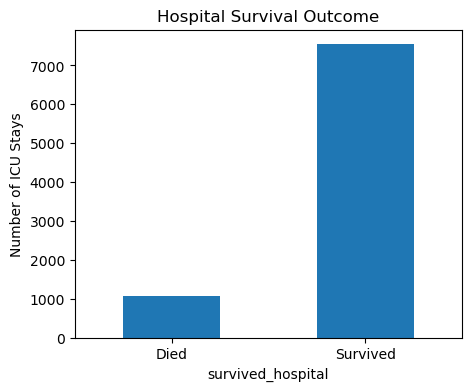

In [12]:
print(df["survived_hospital"].value_counts(normalize=True))

plt.figure(figsize=(5, 4))
df["survived_hospital"].value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["Died", "Survived"], rotation=0)
plt.title("Hospital Survival Outcome")
plt.ylabel("Number of ICU Stays")
plt.show()

# Exploratory Finding: Treatment and Severity

Boxplots compared treatment and severity by hospital survival.

Main pattern:

- Non-survivors generally had higher early SOFA and SIRS scores.
- Higher treatment intensity often appeared among sicker patients.
- Patients who die tend to enter the ICU with higher SOFA scores and it generally remains constant for their stay
- Patients who survive see a constant decline in their SOFA scores, except those who remain in ICU for significant time

**Interpretation:**

Treatment is not randomly assigned. Aggressive treatments are often given to the sickest patients, so raw treatment-outcome associations are confounded by severity.

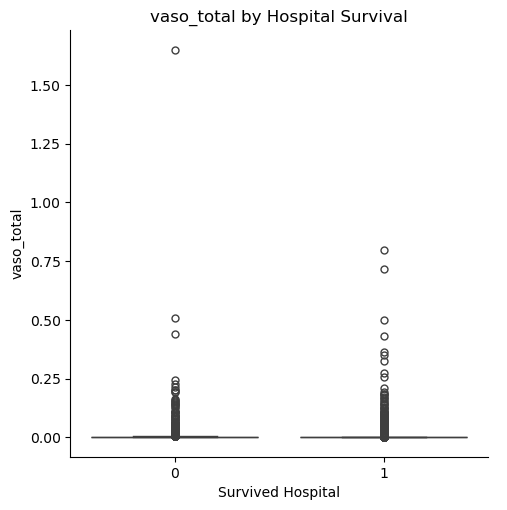

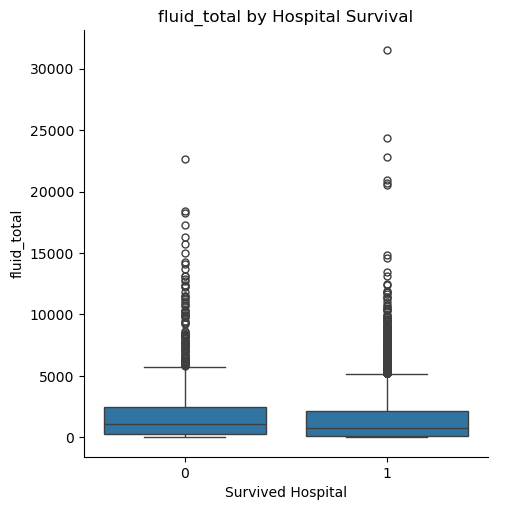

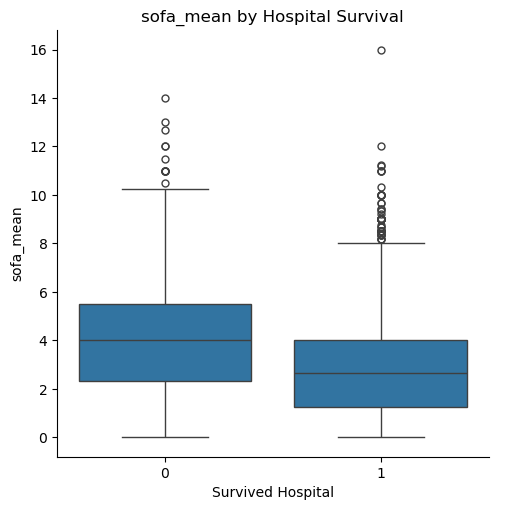

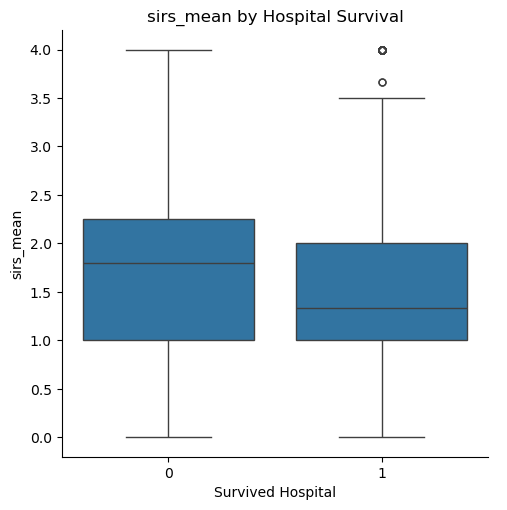

In [65]:
for col in ["vaso_total", "fluid_total", "sofa_mean", "sirs_mean"]:
    eda = sns.catplot(data = df, x = 'survived_hospital', y = col, kind = 'box', orient = 'v')
    eda.set(xlabel = 'Survived Hospital', ylabel = col, title = f"{col} by Hospital Survival")
    


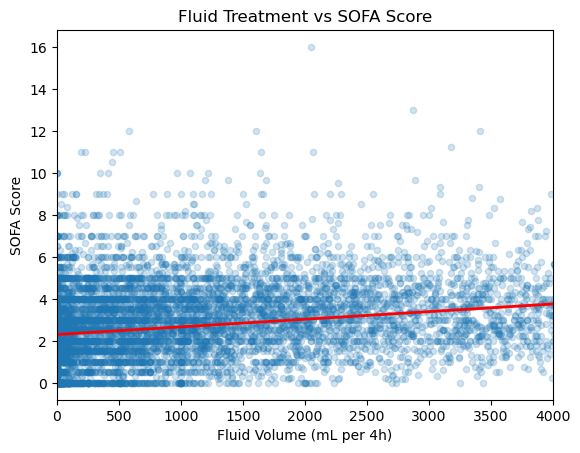

In [67]:
sns.regplot(
    data=df,
    x="fluid_total",
    y="sofa_mean",
    scatter_kws={"alpha": 0.2, "s": 20},
    line_kws={"color": "red", "linewidth": 2}
)
plt.xlim(0,4000)
plt.xlabel("Fluid Volume (mL per 4h)")
plt.ylabel("SOFA Score")
plt.title("Fluid Treatment vs SOFA Score")
plt.show()

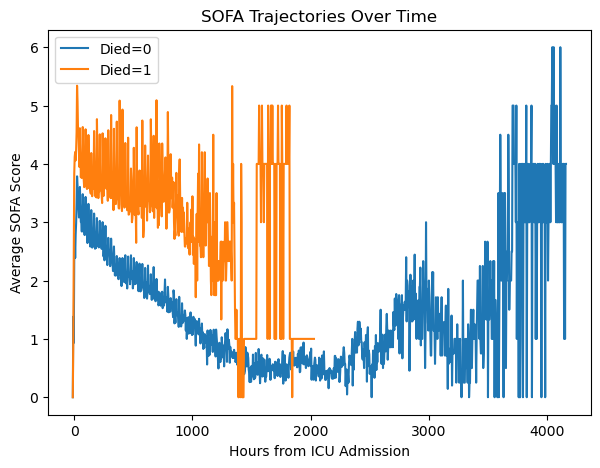

In [66]:
sofa_plot = sofa.merge(
    cohort[["icustay_id", "hospmort"]],
    on="icustay_id",
    how="left"
)
sofa_plot["time_hours"] = sofa_plot["hour_from_admission"]
sofa_trend = sofa_plot.groupby(["time_hours", "hospmort"])["sofa"].mean().reset_index()
plt.figure(figsize=(7,5))
for label, group in sofa_trend.groupby("hospmort"):
    plt.plot(group["time_hours"], group["sofa"], label=f"Died={label}")

plt.xlabel("Hours from ICU Admission")
plt.ylabel("Average SOFA Score")
plt.title("SOFA Trajectories Over Time")
plt.legend()
plt.show()

In [14]:
drop_cols = [
    "icustay_id",
    "hospmort",
    "survived_hospital",
    "is_terminal",
    "outcome",
    "hospmort30day",
    "hospmort1yr",
    'hospital_expire_flag',
    'los_icu',
    'los_hospital'
]

X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y = df["survived_hospital"]

X = X.select_dtypes(include=["int64", "float64"])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Baseline Prediction: Hospital Survival

I compared two models using early 24-hour features:

| Model | Accuracy | ROC AUC |
|---|---:|---:|
| Logistic Regression | 0.767 | 0.810 |
| Random Forest | 0.878 | 0.852 |

**Interpretation:**

The Random Forest performed better, suggesting nonlinear interactions among severity, labs, vitals, and treatments matter for survival prediction.

In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    )
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)
results_df

,model,accuracy,roc_auc
0,Logistic Regression,0.766945,0.810488
1,Random Forest,0.878366,0.851889


# Final Survival Model Performance

Random Forest results:

| Metric | Result |
|---|---:|
| Accuracy | 0.876 |
| ROC AUC | 0.852 |
| Death recall | 0.41 |
| Survival recall | 0.94 |

**Interpretation:**

The model identifies survivors well, but death recall is weaker because death is the minority class. This is an important reliability limitation.

In [16]:
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    ))
])

final_model.fit(X_train, y_train)

pred = final_model.predict(X_test)
prob = final_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, prob))
print(classification_report(y_test, pred))

Accuracy: 0.8760445682451253
ROC AUC: 0.8520998294104307
              precision    recall  f1-score   support

           0       0.50      0.41      0.45       269
           1       0.92      0.94      0.93      1885

    accuracy                           0.88      2154
   macro avg       0.71      0.67      0.69      2154
weighted avg       0.87      0.88      0.87      2154



# Most Important Survival Predictors

Top predictors in the Random Forest survival model:

1. Respiratory rate
2. Admission age
3. BUN
4. Mean SOFA
5. GCS eyes
6. Urine output
7. Systolic blood pressure
8. Lactate
9. Max SOFA
10. Oxygen saturation

**Interpretation:**

Survival prediction is driven mostly by respiratory, renal, neurological, circulatory, and overall severity measures. An important observation is that treatments are not as important as other predictors in survival prediction, but rather the patient's initial severity. 

In [17]:
rf = final_model.named_steps["model"]

importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

importance.head(15)

,feature,importance
19,vital_rr,0.057032
56,admission_age,0.056213
25,lab_bun,0.054250
9,sofa_mean,0.047857
49,gcs_eyes,0.043815
45,uo_total_ml,0.038239
16,vital_sbp,0.033360
31,lab_lactate,0.032408
10,sofa_max,0.025550
21,vital_spo2,0.025499


# Treatment Pattern Clustering

I used K-means clustering on the discrete treatment variables:

- Vasopressor bin
- Fluid bin
- Ventilation bin
- Action ID

**Purpose:**

Instead of studying one treatment at a time, clustering identifies common early treatment strategies across patients.

# Treatment Cluster Profiles

| Cluster | Vaso bin | Fluid bin | Vent bin | Survival | Mean SOFA |
|---|---:|---:|---:|---:|---:|
| 0 | 2.13 | 3.05 | 0.62 | 0.733 | 5.12 |
| 1 | 0.10 | 2.03 | 0.07 | 0.906 | 2.60 |
| 2 | 0.04 | 1.54 | 0.02 | 0.900 | 2.16 |
| 3 | 0.23 | 2.38 | 0.79 | 0.863 | 3.29 |

**Interpretation:**

Cluster 0 received the most aggressive treatment and had the lowest survival, but also the highest SOFA score.

# Cluster Interpretation

The cluster analysis shows a strong relationship between treatment intensity and baseline severity.

- Cluster 0: high vasopressors, high fluids, high ventilation, highest SOFA, lowest survival
- Cluster 1–2: lower intensity treatment, lower SOFA, higher survival
- Cluster 3: high ventilation with moderate fluid use, intermediate survival

**Key point:** Lower survival in aggressive-treatment clusters likely reflects sicker patients receiving more treatment, not treatment causing death.

In [51]:
cluster_data = disc_early.groupby("icustay_id").mean(numeric_only=True).reset_index()

cluster_df = cluster_data.merge(
    df[["icustay_id", "survived_hospital"]],
    on="icustay_id",
    how="left"
)

cluster_X = cluster_df.drop(columns=["icustay_id", "survived_hospital"])

cluster_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cluster_scaled = cluster_pipe.fit_transform(cluster_X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
cluster_df["treatment_cluster"] = kmeans.fit_predict(cluster_scaled)

cluster_df = cluster_df.merge(
    severity[["icustay_id", "sofa_mean", "sofa_max", "sirs_mean", "sirs_max"]],
    on="icustay_id",
    how="left"
)

# Treatment pattern by cluster
cluster_treatment_profile = cluster_df.groupby("treatment_cluster")[
    ["vaso_bin", "fluid_bin", "vent_bin", "action_id"]
].mean()

cluster_survival = cluster_df.groupby("treatment_cluster")[
    "survived_hospital"
].mean()

cluster_severity_profile = cluster_df.groupby("treatment_cluster")[
    ["sofa_mean", "sofa_max", "sirs_mean", "sirs_max"]
].mean()

cluster_treatment_profile.head()

,vaso_bin,fluid_bin,vent_bin,action_id
treatment_cluster,,,,
0,2.125599,3.049423,0.619153,27.973994
1,0.099291,2.032084,0.069368,5.126442
2,0.038617,1.541269,0.022081,3.490792
3,0.229466,2.381674,0.789778,7.847785


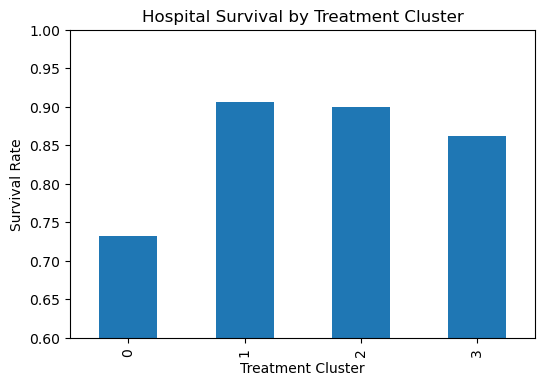

In [52]:
plt.figure(figsize=(6, 4))
cluster_df.groupby("treatment_cluster")["survived_hospital"].mean().plot(kind="bar")
plt.ylim(0.6, 1)
plt.ylabel("Survival Rate")
plt.xlabel("Treatment Cluster")
plt.title("Hospital Survival by Treatment Cluster")
plt.show()

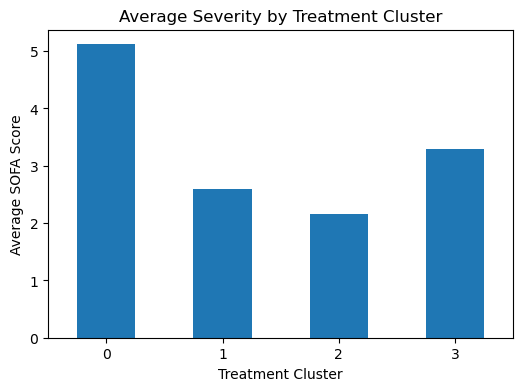

In [20]:
plt.figure(figsize=(6, 4))
cluster_severity_profile["sofa_mean"].plot(kind="bar")
plt.ylabel("Average SOFA Score")
plt.xlabel("Treatment Cluster")
plt.title("Average Severity by Treatment Cluster")
plt.xticks(rotation=0)
plt.show()

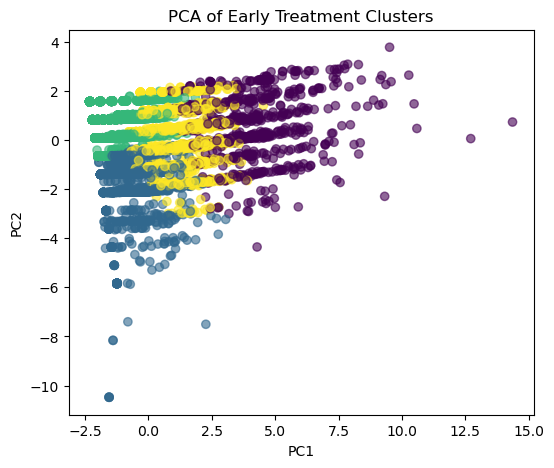

Explained variance: [0.34446473 0.20210796]


In [21]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(cluster_scaled)

plt.figure(figsize=(6, 5))
plt.scatter(
    pcs[:, 0],
    pcs[:, 1],
    c=cluster_df["treatment_cluster"],
    alpha=0.6
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Early Treatment Clusters")
plt.show()

print("Explained variance:", pca.explained_variance_ratio_)

In [22]:
cluster_profile = cluster_df.groupby("treatment_cluster").mean()
cluster_profile

,icustay_id,days,hourrange,vaso_ne_per_kg,fluid_total_ml,mechvent,vaso_bin,fluid_bin,vent_bin,action_id,hour_from_admission,survived_hospital,sofa_mean,sofa_max,sirs_mean,sirs_max
treatment_cluster,,,,,,,,,,,,,,,,
0,248248.949881,-0.002046,4.768150,0.007183,1134.311504,0.619153,2.125599,3.049423,0.619153,27.973994,15.023503,0.732697,5.116911,7.177804,1.751651,2.557279
1,249224.007886,-0.011746,3.791713,0.000070,337.629628,0.069368,0.099291,2.032084,0.069368,5.126442,10.884940,0.906358,2.601526,4.379990,1.439046,2.280434
2,249033.429563,0.000000,5.471700,0.000020,243.274178,0.022081,0.038617,1.541269,0.022081,3.490792,17.886800,0.899913,2.160616,3.030662,1.349026,1.743419
3,251420.914049,-0.001220,4.800402,0.000126,553.358872,0.789778,0.229466,2.381674,0.789778,7.847785,15.172339,0.862565,3.294237,5.001745,1.401605,2.120855


# Why Static Models Are Not Enough

The early summary model answers:

> Do first-24-hour features predict eventual hospital survival?

But we should ask a more dynamic question:

> Given current state and treatment, what happens in the next time window?

So I added transition models using the full 4-hour data structure.

# Dynamic Transition Dataset

I sorted each patient by time and created next-window variables:

```python
sofa_sorted["sofa_next"] = sofa_sorted.groupby("icustay_id")["sofa"].shift(-1)
outcome_sorted["outcome_next"] = outcome_sorted.groupby("icustay_id")["outcome"].shift(-1)
```

**Interpretation:**

Each row now represents:

`current state + current treatment → next state / next outcome`

In [23]:
sofa_sorted = sofa.sort_values(["icustay_id", "hour_from_admission"]).copy()

# Current state -> next state
sofa_sorted["sofa_next"] = sofa_sorted.groupby("icustay_id")["sofa"].shift(-1)
sofa_sorted["sirs_next"] = sofa_sorted.groupby("icustay_id")["sirs"].shift(-1)

# Change in severity
sofa_sorted["sofa_change"] = sofa_sorted["sofa_next"] - sofa_sorted["sofa"]

# Drop rows where no next time window exists
transition_df = sofa_sorted.dropna(subset=["sofa_next"]).copy()

transition_df.head()

,subject_id,hadm_id,icustay_id,days,hourrange,sofa,respiration,coagulation,liver,cardiovascular,...,renal,sirs,temp_score,heartrate_score,resp_score,wbc_score,hour_from_admission,sofa_next,sirs_next,sofa_change
0,55973,152234,200001,0.0,5.0,1,NaN,1.0,NaN,0.0,...,NaN,3,0.0,1.0,1.0,1.0,16.0,3.0,2.0,2.0
1,55973,152234,200001,0.0,6.0,3,NaN,NaN,NaN,0.0,...,3.0,2,0.0,1.0,1.0,NaN,20.0,1.0,2.0,-2.0
2,55973,152234,200001,1.0,1.0,1,NaN,NaN,NaN,1.0,...,NaN,2,NaN,1.0,1.0,NaN,24.0,4.0,2.0,3.0
3,55973,152234,200001,1.0,2.0,4,NaN,1.0,0.0,1.0,...,2.0,2,0.0,1.0,0.0,1.0,28.0,2.0,2.0,-2.0
4,55973,152234,200001,1.0,3.0,2,NaN,NaN,NaN,1.0,...,NaN,2,0.0,1.0,1.0,NaN,32.0,1.0,2.0,-1.0


In [54]:

transition_df = transition_df.merge(
    actions,
    on=["icustay_id", "hour_from_admission"],
    how="left",
    suffixes=("", "_actions") 
)
transition_df = transition_df.merge(
    state,
    on=["icustay_id", "hour_from_admission"],
    how="left",
    suffixes=("", "_state")  
)

transition_df = transition_df.merge(
    outcome,
    on=["icustay_id", "hour_from_admission"],
    how="left",
    suffixes=("", "_outcome") 
)

transition_df = transition_df.merge(
    context,
    on="icustay_id",
    how="left",
    suffixes=("", "_context")  
)

transition_df.shape

(266176, 185)

# Transition Outcomes

The three-class next-window outcome was:

| Outcome | Meaning | Count | Share |
|---|---|---:|---:|
| 0 | Remain | 257,786 | 96.8% |
| 1 | Discharged/survived terminal | 7,310 | 2.7% |
| 2 | Died terminal | 1,080 | 0.4% |

**Interpretation:**

Most 4-hour windows are non-terminal. Death in the next window is very rare, making the multiclass classification problem difficult.

In [25]:
outcome_sorted = outcome.sort_values(["icustay_id", "hour_from_admission"]).copy()

# Next-window terminal status
outcome_sorted["outcome_next"] = outcome_sorted.groupby("icustay_id")["outcome"].shift(-1)


outcome_next = outcome_sorted[[
    "icustay_id",
    "hour_from_admission",
    "outcome_next"
]]

# Drop the existing terminal_next column from transition_df to avoid conflicts
if 'outcome_next' in transition_df.columns:
    transition_df = transition_df.drop('outcome_next', axis=1)

transition_df = transition_df.merge(
    outcome_next,
    on=["icustay_id", "hour_from_admission"],
    how="left"
)

transition_df["outcome_next"] = transition_df["outcome_next"].fillna(0)

transition_df["outcome_next"] = transition_df["outcome_next"].astype(int)

transition_df["outcome_next"].value_counts()

outcome_next
0    257786
1      7310
2      1080
Name: count, dtype: int64

In [55]:

predictor_cols = [
    # severity
    "sofa", "sirs",

    # treatments
    "vaso_ne_per_kg", "fluid_total_ml", "mechvent",

    # vitals
    "vital_hr", "vital_sbp", "vital_dbp", "vital_mbp",
    "vital_rr", "vital_temp_c", "vital_spo2",

    # labs
    "lab_bun", "lab_creatinine", "lab_lactate",
    "lab_platelet", "lab_wbc", "lab_hemoglobin",

    # neurological / output
    "gcs_total", "gcs_motor", "gcs_verbal", "gcs_eyes",
    "uo_total_ml",

    # demographics
    "admission_age", "weight_kg", "height_cm",
    "elixhauser_vanwalraven"
]

# Keep only columns that actually exist
predictor_cols = [c for c in predictor_cols if c in transition_df.columns]

X_transition = transition_df[predictor_cols]

# Model 1: Predicting Next SOFA

Response variable: `sofa_next`

Model: Random Forest Regressor

| Metric | Result |
|---|---:|
| RMSE | 1.75 |
| R² | 0.426 |

**Interpretation:**

The model captures meaningful short-term severity dynamics, but patient trajectories remain noisy and only partly predictable.

In [58]:

y_sofa_next = transition_df["sofa_next"]

X_train, X_test, y_train, y_test = train_test_split(
    X_transition,
    y_sofa_next,
    test_size=0.25,
    random_state=42
)

sofa_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        random_state=42
    ))
])

sofa_model.fit(X_train, y_train)

sofa_pred = sofa_model.predict(X_test)

print("Next SOFA Prediction")
print("RMSE:", np.sqrt(mean_squared_error(y_test, sofa_pred)))
print("R-squared:", r2_score(y_test, sofa_pred))

Next SOFA Prediction
RMSE: 1.7482964814621442
R-squared: 0.4264571369500195


# Model 1: Predicting Next SOFA

Response variable: `sofa_next`

Model: Random Forest Regressor

| Metric | Result |
|---|---:|
| RMSE | 1.75 |
| R² | 0.426 |

**Interpretation:**

The model captures meaningful short-term severity dynamics, but patient trajectories remain noisy and only partly predictable.

In [28]:
sofa_rf = sofa_model.named_steps["model"]

sofa_importance = pd.DataFrame({
    "feature": predictor_cols,
    "importance": sofa_rf.feature_importances_
}).sort_values("importance", ascending=False)

sofa_importance.head(30)

,feature,importance
0,sofa,0.635490
23,admission_age,0.126632
22,uo_total_ml,0.085732
3,fluid_total_ml,0.034341
15,lab_platelet,0.027837
8,vital_mbp,0.021349
2,vaso_ne_per_kg,0.012540
14,lab_lactate,0.008049
13,lab_creatinine,0.007087
12,lab_bun,0.007084


# Model 2: Predicting Next Outcome

Response variable: `outcome_next`

- 0 = remain
- 1 = discharged/survived terminal
- 2 = died terminal

Random Forest Classifier results:

| Class | Precision | Recall | F1 |
|---|---:|---:|---:|
| Remain | 0.99 | 0.60 | 0.75 |
| Discharged | 0.07 | 0.90 | 0.12 |
| Died | 0.06 | 0.60 | 0.11 |

Overall accuracy: 0.60

# Interpreting the Next-Outcome Model

The model detects many terminal events, but precision is low for discharge and death.

**Why?**

- Terminal windows are rare.
- Death is only about 0.4% of next-window observations.
- Class weighting increases recall for rare events but creates false positives.

**Conclusion:**

This model is useful as a warning signal, not as a precise terminal-outcome classifier.

In [59]:

y_multi = transition_df["outcome_next"]

X_train, X_test, y_train, y_test = train_test_split(
    X_transition,
    y_multi,
    test_size=0.25,
    random_state=42,
    stratify=y_multi
)

multi_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    ))
])

multi_model.fit(X_train, y_train)

pred = multi_model.predict(X_test)
prob = multi_model.predict_proba(X_test)

from sklearn.metrics import classification_report

print(classification_report(y_test, pred))


              precision    recall  f1-score   support

           0       0.99      0.60      0.75     64447
           1       0.07      0.90      0.12      1827
           2       0.06      0.61      0.11       270

    accuracy                           0.60     66544
   macro avg       0.37      0.70      0.33     66544
weighted avg       0.96      0.60      0.73     66544



# Counterfactual Fluid Analysis

To approximate a treatment effect, I compared two predictions for the same patient-window:

1. Set `fluid_total_ml` to a typical positive fluid level
2. Set `fluid_total_ml` to 0

Everything else stays fixed.

**Goal:** Estimate how fluid administration is associated with next SOFA and next-outcome probabilities.

# Fluid Effect on Next SOFA

Average predicted effect of fluids on next SOFA:

| Quantity | Estimate |
|---|---:|
| Fluid effect on next SOFA | +0.213 |

**Interpretation:**

Fluid administration is associated with a slightly higher next SOFA score. This should not be interpreted as fluids causing deterioration. More likely, clinicians give fluids when patients are already unstable or worsening.

In [31]:

X_fluid = X_cf.copy()
X_no_fluid = X_cf.copy()

if "fluid_total_ml" in X_cf.columns:
    X_fluid["fluid_total_ml"] = X_cf["fluid_total_ml"].median()
    X_no_fluid["fluid_total_ml"] = 0

    sofa_next_fluid = sofa_model.predict(X_fluid)
    sofa_next_no_fluid = sofa_model.predict(X_no_fluid)

    transition_df["fluid_effect_on_next_sofa"] = sofa_next_fluid - sofa_next_no_fluid

    print("Average predicted effect of fluids on next SOFA:")
    print(transition_df["fluid_effect_on_next_sofa"].mean())

Average predicted effect of fluids on next SOFA:
0.21292275220601145


# Fluid Effect on Next Outcome

Average predicted change in next-window outcome probabilities:

| Outcome | Change in Probability |
|---|---:|
| Death | +0.0025 |
| Discharge | -0.0491 |
| Remain | +0.0467 |

**Interpretation:**

In the model, fluid treatment is associated with a lower probability of immediate discharge and a higher probability of remaining hospitalized. This likely reflects treatment being given to patients who need continued care.

In [34]:
X_cf = X_transition.copy()

X_fluid = X_cf.copy()
X_no_fluid = X_cf.copy()

# simulate giving fluids vs no fluids
if "fluid_total_ml" in X_cf.columns:

    # "treated" = typical fluid level (use median)
    X_fluid["fluid_total_ml"] = X_cf["fluid_total_ml"].median()

    # "untreated" = no fluids
    X_no_fluid["fluid_total_ml"] = 0

    # predict probabilities for each outcome
    prob_fluid = multi_model.predict_proba(X_fluid)
    prob_no_fluid = multi_model.predict_proba(X_no_fluid)

    # class indices:
    # 0 = remain, 1 = discharged, 2 = died

    death_effect = prob_fluid[:, 2] - prob_no_fluid[:, 2]
    discharge_effect = prob_fluid[:, 1] - prob_no_fluid[:, 1]
    remain_effect = prob_fluid[:, 0] - prob_no_fluid[:, 0]

    print("Fluid effect on death probability:", death_effect.mean())
    print("Fluid effect on discharge probability:", discharge_effect.mean())
    print("Fluid effect on remaining in hospital:", remain_effect.mean())

Fluid effect on death probability: 0.0027736511257665814
Fluid effect on discharge probability: -0.048881922550812605
Fluid effect on remaining in hospital: 0.04610827142504939


In [35]:
transition_df["fluid_death_effect"] = death_effect
transition_df["fluid_discharge_effect"] = discharge_effect
transition_df["fluid_remain_effect"] = remain_effect


# Heterogeneity by Age

Fluid effect on next-window outcomes:

| Age Group | Death Effect | Discharge Effect |
|---|---:|---:|
| Under 50 | +0.0014 | -0.0489 |
| 50–70 | +0.0011 | -0.0510 |
| Over 70 | +0.0022 | -0.0503 |

**Interpretation:**

Effects are similar across age groups. Older patients show a slightly larger increase in predicted death probability, but the difference is small.

In [ ]:

if "admission_age" in transition_df.columns:
    transition_df["age_group"] = pd.cut(
        transition_df["admission_age"],
        bins=[0, 50, 70, 120],
        labels=["Under 50", "50-70", "Over 70"]
    )

    age_effects = transition_df.groupby("age_group")[
        ["fluid_effect_on_next_sofa"]
    ].mean()

    print(age_effects)

In [36]:
transition_df["age_group"] = pd.cut(
    transition_df["admission_age"],
    bins=[0, 50, 70, 100],
    labels=["Under 50", "50-70", "Over 70"]
)

fluid_age_effects = transition_df.groupby("age_group")[
    ["fluid_death_effect", "fluid_discharge_effect"]
].mean()

print(fluid_age_effects)

           fluid_death_effect  fluid_discharge_effect
age_group                                            
Under 50             0.001823               -0.048816
50-70                0.001486               -0.051334
Over 70              0.002400               -0.050954


C:\Users\ethan\AppData\Local\Temp\ipykernel_3056\1449535407.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fluid_age_effects = transition_df.groupby("age_group")[


# Heterogeneity by Severity

Fluid effect on next-window outcomes:

| Severity Group | Death Effect | Discharge Effect |
|---|---:|---:|
| Low SOFA | +0.0031 | -0.0520 |
| Moderate SOFA | +0.0021 | -0.0472 |
| High SOFA | -0.0041 | -0.0270 |

**Interpretation:**

The relationship differs more by severity than by age. In high-SOFA patients, fluids are associated with a lower predicted death probability, while in lower-SOFA groups fluids are associated with delayed discharge and slightly higher predicted death probability.

In [37]:
transition_df["severity_group"] = pd.cut(
    transition_df["sofa"],
    bins=[-1, 3, 7, 25],
    labels=["Low SOFA", "Moderate SOFA", "High SOFA"]
)

fluid_severity_effects = transition_df.groupby("severity_group")[
    ["fluid_death_effect", "fluid_discharge_effect"]
].mean()

print(fluid_severity_effects)

                fluid_death_effect  fluid_discharge_effect
severity_group                                            
Low SOFA                  0.003164               -0.051226
Moderate SOFA             0.002693               -0.047483
High SOFA                -0.003210               -0.027362


C:\Users\ethan\AppData\Local\Temp\ipykernel_3056\3874039542.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fluid_severity_effects = transition_df.groupby("severity_group")[


# Main Findings

1. Early ICU state and treatments predict hospital survival reasonably well.
2. Severity, age, respiratory status, renal markers, neurological status, and urine output are major survival predictors.
3. Aggressive treatment clusters have lower survival, but they also have much higher SOFA scores.
4. Current SOFA is the strongest predictor of next SOFA.
5. Fluid treatment is associated with higher next SOFA and lower immediate discharge probability.
6. Fluid-response patterns differ more by baseline severity than by age.

# Final Conclusion

Early ICU treatments are strongly associated with short-term patient trajectories, but those associations are heavily shaped by baseline severity.

The most defensible conclusion is:

> Fluids and other aggressive treatments are markers of clinical instability. Their apparent relationship with worse outcomes largely reflects confounding by indication, although heterogeneity by SOFA suggests treatment-response patterns differ across severity groups.

Therefore, the results should be interpreted as predictive and associational rather than strictly causal.

# Limitations

Limitations:

- Treatment is not randomized
- Missingness may be informative
- Rare terminal outcomes reduce precision
- Counterfactual estimates are model-based, not causal proof
- Median imputation is simple and may miss missingness patterns

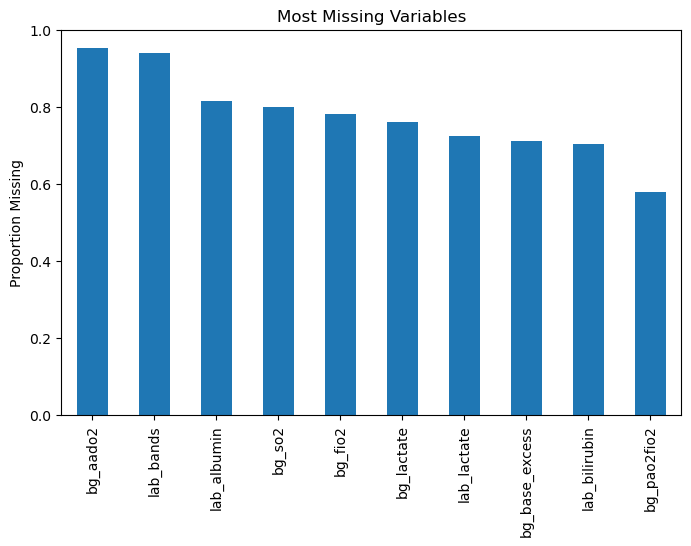

In [44]:
missing = state.isna().mean().sort_values(ascending=False)

plt.figure(figsize=(8,5))
missing.head(10).plot(kind="bar")

plt.title("Most Missing Variables")
plt.ylabel("Proportion Missing")
plt.show()

# Thanks for a Great Semester!